# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "narela_armani", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

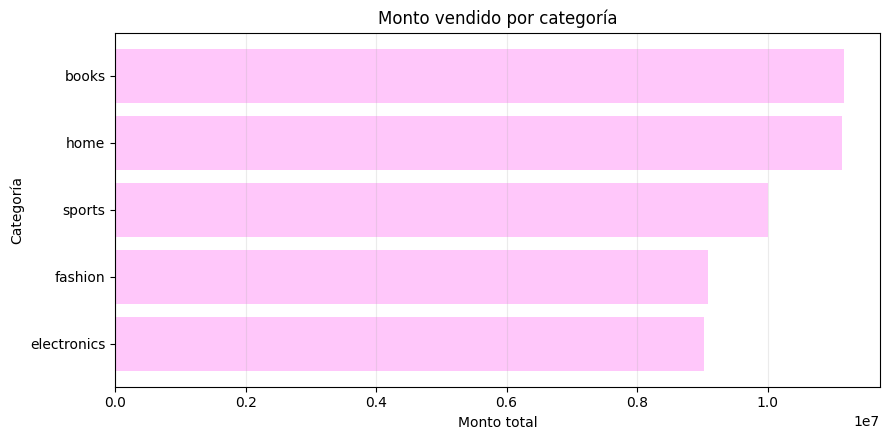

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#FFC7FA")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

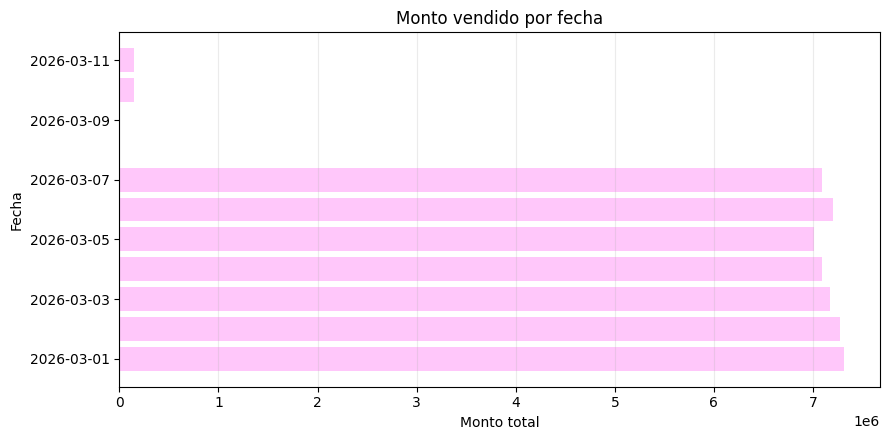

Respuesta: 2026-03-01 es la fecha con mayor monto vendido 7,310,840.77


In [0]:
# Tu solución. Agregá por sale_date antes de convertir el resultado a Pandas.
# Incluí título, ejes, unidades y una respuesta escrita.

sale_date = spark.table(daily).groupBy("sale_date").agg(F.sum("total_amount").alias("total_amount")).orderBy(F.desc("total_amount"))
plot_data = sale_date.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["sale_date"], plot_data["total_amount"], color="#FFC7FA")
ax.set_title("Monto vendido por fecha")
ax.set_xlabel("Monto total")
ax.set_ylabel("Fecha")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = sale_date.first()
print(f"Respuesta: {leader.sale_date} es la fecha con mayor monto vendido {leader.total_amount:,.2f}")

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

payment_channel,transactions,fraud_transactions,fraud_rate
transfer,16723,2327,0.1391496741015368
wallet,16724,2169,0.1296938531451806
card,16902,2119,0.12536977872441132


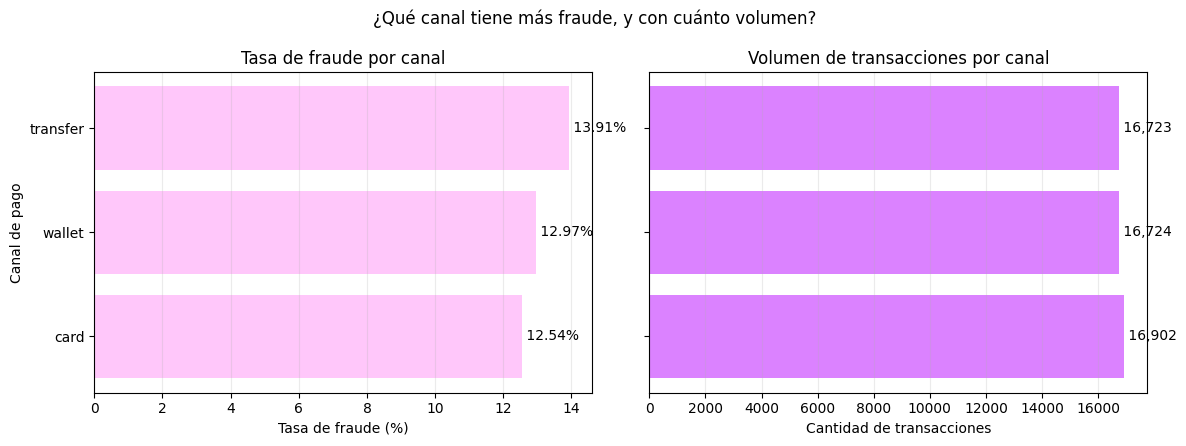

Respuesta: transfer tiene la mayor tasa de fraude (13.91%: 2327 fraudes sobre 16,723 transacciones, 33.2% del volumen total).


In [0]:
# Tu solución. Recalculá la tasa global como suma(fraud_transactions) / suma(transaction_count).
# Evitá promediar directamente fraud_rate entre grupos.

# 1) AGREGACIÓN EN SPARK
# gold_daily_sales tiene varias filas por canal (una por día × país × categoría × canal),
# así que agrupamos por canal y SUMAMOS numerador y denominador por separado.
channel_fraud = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("transaction_count").alias("transactions"),        # denominador
        F.sum("fraud_transactions").alias("fraud_transactions"), # numerador
    )
    # La tasa se calcula DESPUÉS de sumar, no promediando la columna fraud_rate
    .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transactions"))
    .orderBy(F.desc("fraud_rate")))

display(channel_fraud)

# 2) PASAR A PANDAS SOLO EL RESULTADO CHICO (una fila por canal)
plot_data = channel_fraud.toPandas().sort_values("fraud_rate")
plot_data["fraud_pct"] = plot_data["fraud_rate"] * 100

# 3) GRÁFICO: dos paneles que comparten el eje de canales (tasa y volumen tienen unidades distintas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ax1.barh(plot_data["payment_channel"], plot_data["fraud_pct"], color="#FFC7FA")
ax1.set_title("Tasa de fraude por canal")
ax1.set_xlabel("Tasa de fraude (%)")
ax1.set_ylabel("Canal de pago")
ax1.grid(axis="x", alpha=0.25)
for y, v in enumerate(plot_data["fraud_pct"]):
    ax1.text(v, y, f" {v:.2f}%", va="center")   # etiqueta con el valor: el color no es el único código

ax2.barh(plot_data["payment_channel"], plot_data["transactions"], color="#DB82FF")
ax2.set_title("Volumen de transacciones por canal")
ax2.set_xlabel("Cantidad de transacciones")
ax2.grid(axis="x", alpha=0.25)
for y, v in enumerate(plot_data["transactions"]):
    ax2.text(v, y, f" {v:,}", va="center")

fig.suptitle("¿Qué canal tiene más fraude, y con cuánto volumen?")
fig.tight_layout()
plt.show()

# 4) RESPUESTA
total_tx = plot_data["transactions"].sum()
leader = channel_fraud.first()
print(f"Respuesta: {leader.payment_channel} tiene la mayor tasa de fraude "
      f"({leader.fraud_rate:.2%}: {leader.fraud_transactions} fraudes sobre {leader.transactions:,} transacciones, "
      f"{leader.transactions / total_tx:.1%} del volumen total).")

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

country,category,ventas_totales
BR,home,2361959.97
UY,home,2323924.46
AR,books,2267722.26
BR,books,2252988.52
UY,books,2252955.97
MX,books,2235941.63
AR,home,2184148.34
CL,home,2167748.03
CL,books,2155673.48
MX,home,2105216.34


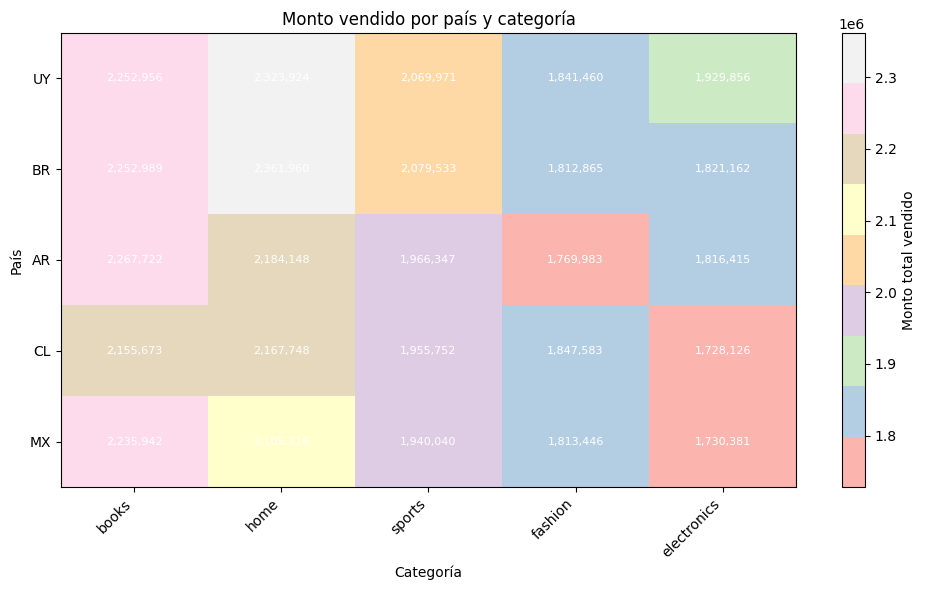

Máximo global: BR × home con 2,361,959.97

Categoría líder en cada país:
  UY: home (2,323,924.46)
  BR: home (2,361,959.97)
  AR: books (2,267,722.26)
  CL: home (2,167,748.03)
  MX: books (2,235,941.63)

La categoría líder cambia según el país (2 categorías distintas lideran).


In [0]:
# Tu solución. Algunas opciones: mapa de calor o barras agrupadas.
# La conclusión debe mencionar tanto el máximo global como las diferencias entre países.

# PASO 0 — Agregación en Spark (una fila por país × categoría)
country_cat = (spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").cast("double").alias("ventas_totales"))
    .orderBy(F.desc("ventas_totales")))

display(country_cat)

# PASO 1 — Resultado chico a Pandas y de tabla "larga" a matriz
plot_data = country_cat.toPandas()
pivot = plot_data.pivot(index="country", columns="category", values="ventas_totales").fillna(0)

# PASO 2 — Ordenar filas (países) y columnas (categorías) de mayor a menor total
pivot = pivot.loc[
    pivot.sum(axis=1).sort_values(ascending=False).index,
    pivot.sum(axis=0).sort_values(ascending=False).index
]

# PASO 3 — Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pivot.values, cmap="Pastel1", aspect="auto")

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

umbral = pivot.values.max() / 2
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        valor = pivot.iat[i, j]
        ax.text(j, i, f"{valor:,.0f}", ha="center", va="center", fontsize=8,
                color="white" if valor > umbral else "black")

fig.colorbar(im, ax=ax, label="Monto total vendido")
ax.set_title("Monto vendido por país y categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("País")
fig.tight_layout()
plt.show()

# PASO 4 — Respuestas
pais_max, cat_max = pivot.stack().idxmax()
print(f"Máximo global: {pais_max} × {cat_max} con {pivot.loc[pais_max, cat_max]:,.2f}\n")

lideres = pivot.idxmax(axis=1)
print("Categoría líder en cada país:")
for pais, cat in lideres.items():
    print(f"  {pais}: {cat} ({pivot.loc[pais, cat]:,.2f})")

if lideres.nunique() == 1:
    print(f"\n{lideres.iloc[0]} domina en todos los países.")
else:
    print(f"\nLa categoría líder cambia según el país ({lideres.nunique()} categorías distintas lideran).")


## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

source_batch_id,accepted_transactions,rejected_transactions,total,proporcion_aprobados,proporcion_rechazados
initial,49948,51,49999,0.998979979599592,0.0010200204004080081
batch_002,200,2,202,0.9900990099009901,0.009900990099009901
batch_003,201,2,203,0.9901477832512315,0.009852216748768473


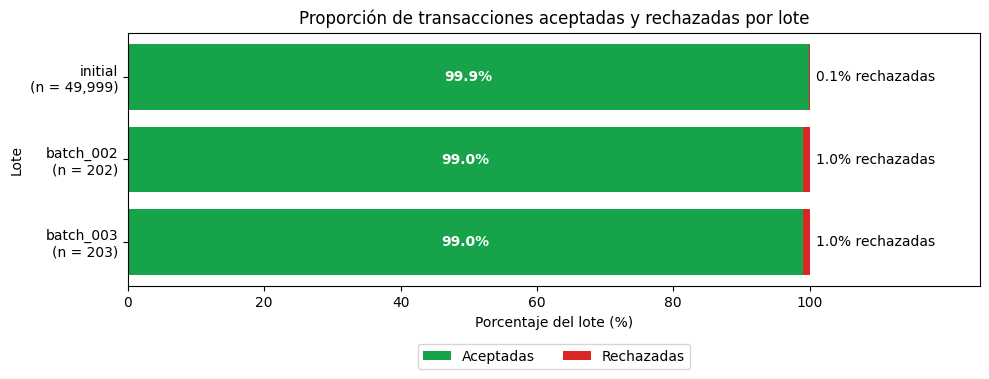

initial: 49,999 transacciones → 99.9% aceptadas, 0.1% rechazadas
batch_002: 202 transacciones → 99.0% aceptadas, 1.0% rechazadas
batch_003: 203 transacciones → 99.0% aceptadas, 1.0% rechazadas


In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.

# PASO 1 — Proporciones (la tabla ya tiene una fila por lote: no hace falta groupBy ni agg)
proporcion = (spark.table(batch)
    .withColumn("total", F.col("accepted_transactions") + F.col("rejected_transactions"))
    .withColumn("proporcion_aprobados", F.col("accepted_transactions") / F.col("total"))
    .withColumn("proporcion_rechazados", F.col("rejected_transactions") / F.col("total"))
    # Orden cronológico: 'initial' primero, después los batch en orden
    .orderBy(F.when(F.col("source_batch_id") == "initial", 0).otherwise(1), "source_batch_id"))

display(proporcion.select("source_batch_id", "accepted_transactions", "rejected_transactions",
                          "total", "proporcion_aprobados", "proporcion_rechazados"))

# PASO 2 — A Pandas (3 filas) y pasar a porcentaje
plot_data = proporcion.toPandas()
plot_data["pct_aprobados"] = plot_data["proporcion_aprobados"] * 100
plot_data["pct_rechazados"] = plot_data["proporcion_rechazados"] * 100

# Etiqueta de cada barra con el tamaño del lote, para no ocultar que son de tamaños distintos
etiquetas = [f"{lote}\n(n = {total:,})"
             for lote, total in zip(plot_data["source_batch_id"], plot_data["total"])]

# PASO 3 — Barras apiladas al 100%
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(etiquetas, plot_data["pct_aprobados"], color="#16a34a", label="Aceptadas")
ax.barh(etiquetas, plot_data["pct_rechazados"], left=plot_data["pct_aprobados"],
        color="#dc2626", label="Rechazadas")

# Valores escritos: el % aceptado dentro de la barra verde, el % rechazado a la derecha
for y, (ok, bad) in enumerate(zip(plot_data["pct_aprobados"], plot_data["pct_rechazados"])):
    ax.text(ok / 2, y, f"{ok:.1f}%", ha="center", va="center", color="white", fontweight="bold")
    ax.text(101, y, f"{bad:.1f}% rechazadas", ha="left", va="center")

ax.set_xlim(0, 125)                 # espacio extra a la derecha para el texto
ax.set_xticks(range(0, 101, 20))    # pero el eje solo marca de 0 a 100
ax.invert_yaxis()                   # 'initial' arriba
ax.set_title("Proporción de transacciones aceptadas y rechazadas por lote")
ax.set_xlabel("Porcentaje del lote (%)")
ax.set_ylabel("Lote")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
plt.show()

# PASO 4 — Resumen para la respuesta
for row in proporcion.collect():
    print(f"{row.source_batch_id}: {row.total:,} transacciones → "
          f"{row.proporcion_aprobados:.1%} aceptadas, {row.proporcion_rechazados:.1%} rechazadas")

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.